In [1]:
library(Seurat)
library(stringr)
library(ggplot2)
library(ggpubr)
library(viridis)
library(rtracklayer)
library(tidyr)
library(GenomicRanges)
library(Signac)
library(AnnotationHub)
library(reshape2)
library(GenomicRanges)
library(BSgenome.Hsapiens.UCSC.hg38)
library(BSgenome)
library(patchwork)
library(ggrastr)
library(cowplot)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Loading required package: viridisLite

Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:SeuratObject’:

    intersect


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading 

## Loading and processed the 10X Transcriptome data after filtering residual T7 reads from transcriptome
The raw data was processed with *06_process_transcriptome_post-T7-filtering.ipynb*, which (briefly):

- Filtered cells with fewer than 1,300 UMIs + 1,000 genes, as well as cells with 5% or more mitochondrial reads
- Ran standard Seurat data normalization and dimensionality reduction functions
- Added T7-associations supported by greater than 10 UMIs

Resulting in the final object we are loading here:

In [2]:
obj <- readRDS("../../top-100_10X-capture/t7-filtered.K562-L1-L2.normalized-obj.rds")

## Supplementary Figure 11
###  Performance of T7 IST–enabled single-cell profiling and assignment of cCRE deletions
Function to read in the T7 associations (processed with ***count_K562-T7_associations.ipynb***):

In [3]:
load_t7 <- function(rep,cutoff=10) {
    t7.path <- paste0("../../top-100_10X-capture/t7_K562_",rep,".associations.tsv")
    t7_counts <- read.table(t7.path,header=TRUE)
    t7_counts <- t7_counts[t7_counts$umis >= cutoff & t7_counts$reads >= cutoff,]
    t7_counts$cbc <- paste0(rep,"_",t7_counts$cbc)
    t7_counts$rep <- rep
    t7_counts
    }

Visualizing the number of reads versus UMIs for each association:

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


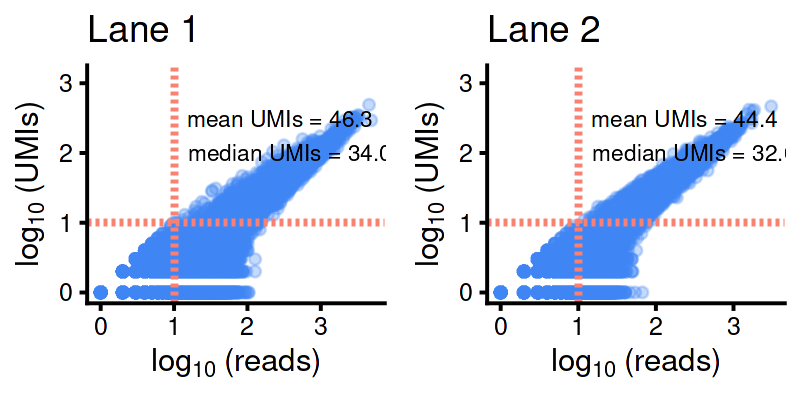

In [4]:
l1_counts <- load_t7("L1",cutoff=0)
l2_counts <- load_t7("L2",cutoff=0)


plot_t7 <- function(df,title) {
    
    mean_   <- mean(df[df$reads >= 10 & df$umis >= 10, ]$umis)
    median_ <- median(df[df$reads >= 10 & df$umis >= 10, ]$umis)
    
    ggplot(df,aes(x=log10(reads),y=log10(umis))) + 
      geom_point_rast(alpha=.3,color="#4287f5") + 
      theme_classic() +
      theme(axis.line = element_line(color = "black"),
           ) + 
      ylab(bquote(log[10]~"(UMIs)")) +
      xlab(bquote(log[10]~"(reads)")) + 
      geom_hline(yintercept=log10(10),linetype="dashed",color="salmon",size=1) + 
      geom_vline(xintercept=log10(10),linetype="dashed",color="salmon",size=1) + 
      ggtitle(title) +
      annotate(
          "text",
          x = 1.05, y = 3.1,
          label = sprintf("mean UMIs = %.1f", mean_),
          hjust = -0.05, vjust = 3, size = 8/.pt
        ) +
        annotate(
          "text",
          x = 1.05, y = 3.101,
          label = sprintf("median UMIs = %.1f", median_),
          hjust = -0.05, vjust = 5, size = 8/.pt
        )
    
    }

a <- plot_t7(l1_counts,"Lane 1")
b <- plot_t7(l2_counts,"Lane 2")

options(repr.plot.width = 4, repr.plot.height = 2, repr.plot.res = 200)
ggarrange(a,b,
          ncol=2,
          nrow=1)

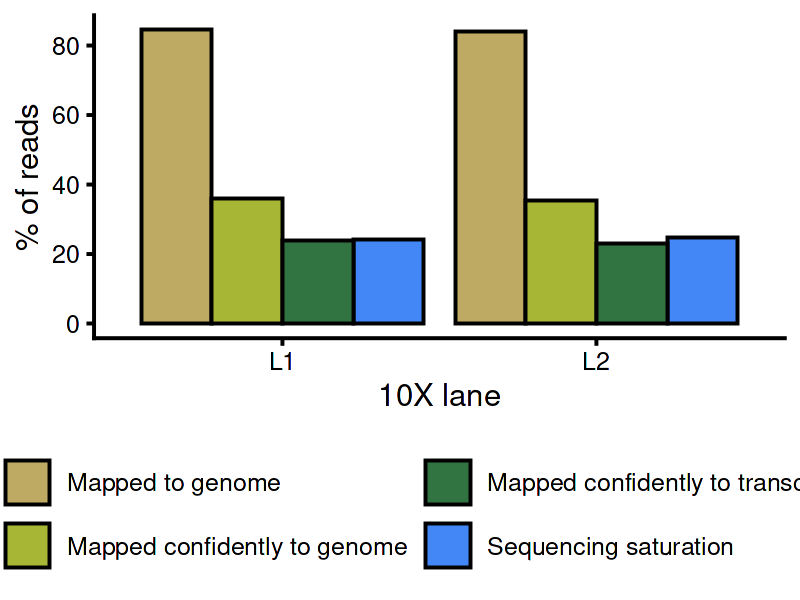

In [5]:
read_10X_metrics <- function(lane) {
    path <- "../../top-100_10X-capture/count_RNA/t7_filtered_counts/t7-filtered_RNA_"

    file_path <- paste0(path,lane,"/outs/metrics_summary.csv")

    df <- read.csv(file_path,sep=",",header=TRUE)
    df$lane <- lane
    df
}

df <- rbind(read_10X_metrics("L1"),read_10X_metrics("L2"))

pct_cols <- c(
  "Sequencing.Saturation",
  "Reads.Mapped.to.Genome",
  "Reads.Mapped.Confidently.to.Genome",
  "Reads.Mapped.Confidently.to.Transcriptome"
)

df[pct_cols] <- lapply(df[pct_cols], function(x)
  as.numeric(gsub("%", "", x))
)

df_long <- df |>
  pivot_longer(
    cols = all_of(pct_cols),
    names_to = "metric",
    values_to = "percent"
  )

metric_order <- c(
  "Reads.Mapped.to.Genome",
  "Reads.Mapped.Confidently.to.Genome",
  "Reads.Mapped.Confidently.to.Transcriptome",
  "Sequencing.Saturation"
)
df_long$metric <- factor(
  df_long$metric,
  levels = metric_order,
  labels = c(
    "Mapped to genome",
    "Mapped confidently to genome",
    "Mapped confidently to transcriptome",
    "Sequencing saturation"
  )
)

set.seed(13)
c <- ggplot(df_long, aes(x = lane, y = percent, fill = metric)) +
  geom_col(
    position = position_dodge(width = .9),
    color = "black"
  ) +
  theme_classic() +
  theme(legend.position="bottom",
    axis.line = element_line(color = "black")
  ) +
  ylab("% of reads") +
  xlab("10X lane") +
  scale_fill_manual(values=c('#beaa62','#a8b635','#317341','#4287f5')) +
  labs(fill="")+ guides(fill = guide_legend(nrow = 2))

options(repr.plot.width = 4, repr.plot.height = 3, repr.plot.res = 200)
c

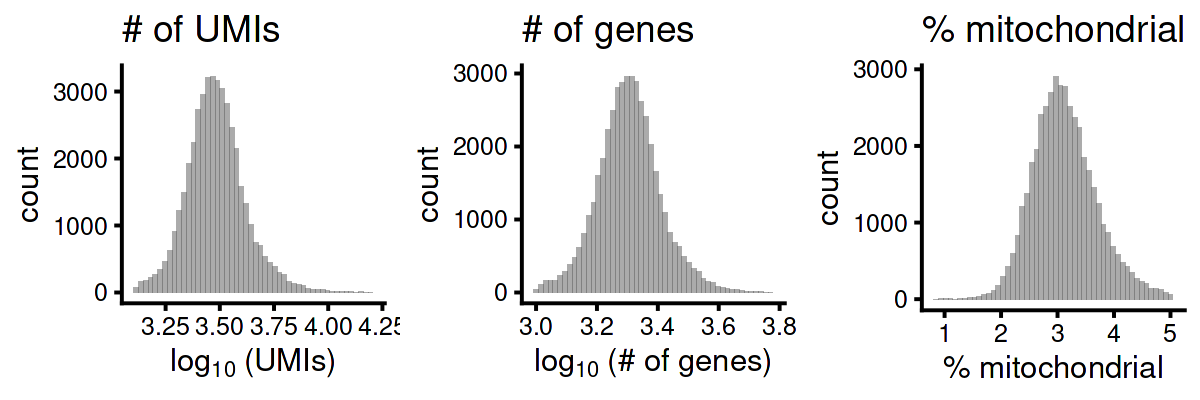

In [6]:
d <- ggplot(obj@meta.data,aes(x=log10(nCount_RNA))) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        legend.position = "none") + 
  xlab(bquote(log[10]~"(UMIs)")) + 
  ggtitle("# of UMIs")

e <- ggplot(obj@meta.data,aes(x=log10(nFeature_RNA))) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        legend.position = "none") + 
  xlab(bquote(log[10]~"(# of genes)")) + 
  ggtitle("# of genes")

f <- ggplot(obj@meta.data,aes(x=percent.mt)) + geom_histogram(bins=50,alpha=.5) + 
  theme_classic() +
  theme(axis.line  = element_line(color = "black"),
        legend.position = "none") + 
  xlab("% mitochondrial") +
  ggtitle("% mitochondrial")

options(repr.plot.width = 6, repr.plot.height = 2, repr.plot.res = 200)
ggarrange(d,e,f, ncol=3, nrow=1)

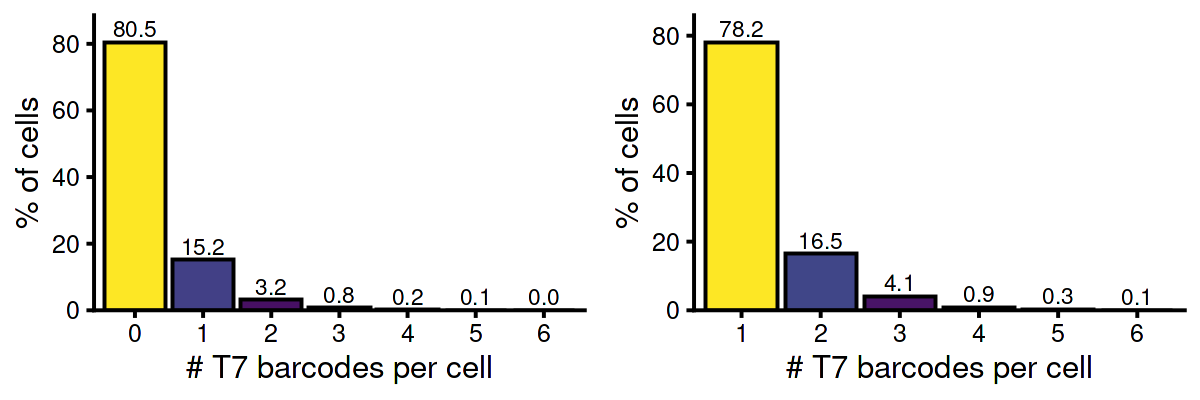

In [7]:
lb <- obj@meta.data$location_barcode

obj@meta.data$n_deletions <- ifelse(
  lb == "" | is.na(lb),
  0,
  stringr::str_count(lb, "_") + 1
)

t7.counts <- as.data.frame(table(obj@meta.data$n_deletions))
t7.counts$perc <- 100*t7.counts$Freq / sum(t7.counts$Freq )


bar_plot <- function(df) {
  df$perc_lab <- sprintf("%.1f", df$perc)

  ggplot(df, aes(x = Var1, y = perc, fill = perc)) +
    geom_col(color = "black") +
    geom_text(
      aes(label = perc_lab),
      vjust = -0.3,
      size = 8/.pt
    ) +
    scale_y_continuous(expand = expansion(mult = c(0, 0.10))) +
    theme_classic() +
    theme(
      legend.position = "none"
    ) +
    xlab("# T7 barcodes per cell") +
    ylab("% of cells") +
    scale_fill_viridis()
}


t7.single <- t7.counts[t7.counts$Var1 != "0",]
t7.single$perc <- 100*t7.single$Freq / sum(t7.single$Freq )

g <- bar_plot(t7.counts)
h <- bar_plot(t7.single)
options(repr.plot.width = 6, repr.plot.height = 2, repr.plot.res = 200)

ggarrange(g,h,ncol=2,nrow=1)

Number of cells assigned a deletion per cCRE (including cells with multiple deletions assigned):

In [8]:
n_cells <- as.data.frame(matrix(ncol=0,nrow=0))

CREs <- unique(obj@meta.data[obj@meta.data$CRE_id != "" &
              grepl("_",obj@meta.data$CRE_id) == FALSE,]$CRE_id)
for (CRE in CREs) {
        n_cells <- rbind(n_cells,c(CRE,nrow(obj@meta.data[grepl(CRE,obj@meta.data$CRE_id) == TRUE,])))
}

colnames(n_cells) <- c("CRE","n.cells")
n_cells$n.cells <- as.numeric(n_cells$n.cells)
n_cells <- n_cells[order(-n_cells$n.cells),]
n_cells$CRE <- factor(n_cells$CRE, levels = n_cells$CRE)

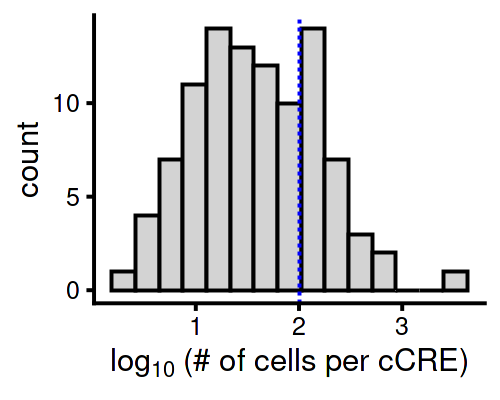

In [9]:
options(repr.plot.width = 2.5, repr.plot.height = 2, repr.plot.res = 200)
i <- ggplot(n_cells,aes(x=log10(n.cells))) + 
        geom_histogram(bins=15,fill="lightgrey",color="black") + 
        geom_vline(xintercept=log10(100),linetype="dashed",color="blue") +
        theme_classic() +
        xlab(bquote(log[10]~"(# of cells per cCRE)"))
i

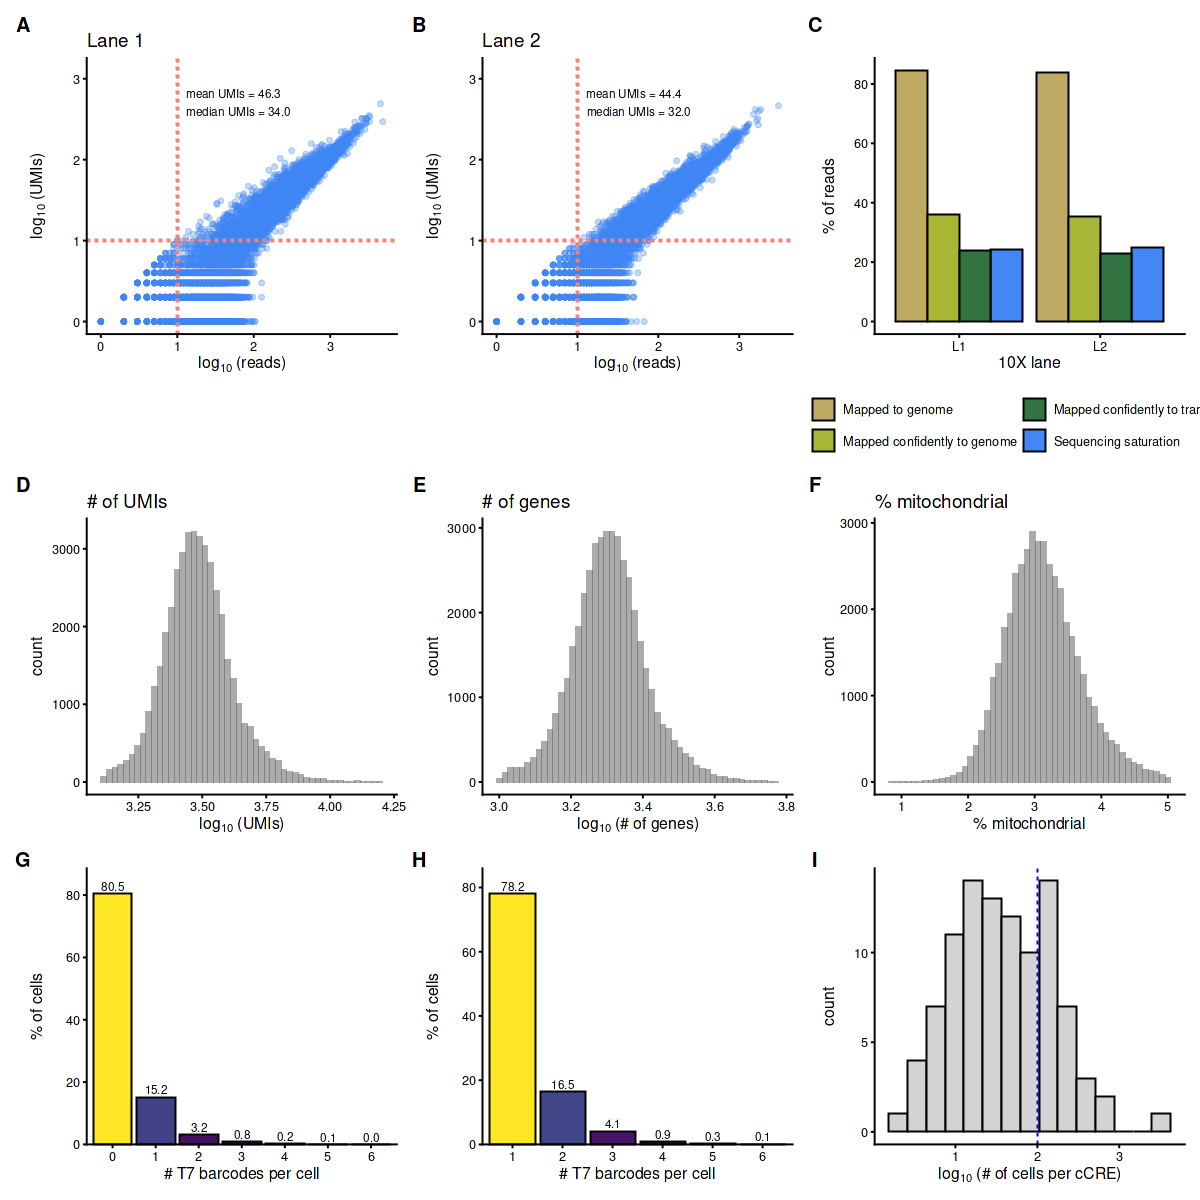

In [10]:
library(patchwork)

layout <- "
ABC
DEF
GHI"

options(repr.plot.width = 12, repr.plot.height = 12, repr.plot.res = 100)
fig <- (a + b + c + d + e + f + g + h + i) +
  plot_layout(design = layout) +
  plot_annotation(tag_levels = "A") &
  theme(
    plot.tag = element_text(
      face = "bold",
      size = 14
    )
  )

fig

In [11]:
ggsave("../figures/SuppFig11.pdf", 
       plot = fig, 
       width = 210, 
       height = 210, 
       useDingbats = F, 
       units = 'mm', 
       device = 'pdf')

## Supplementary Figure 12
###  Template-dependent variation in T7 UMI abundance across edited cCREs

In [12]:
l1.t7 <- load_t7("L1")
l2.t7 <- load_t7("L2")

t7 <- rbind(l1.t7,l2.t7)

location_mapping <- unique(obj@meta.data[obj@meta.data$location_barcode != "" &
                                        grepl("_",obj@meta.data$location_barcode) == FALSE,
                                         c("location_barcode","CRE_id")])

t7$CRE <- location_mapping$CRE_id[match(t7$location_barcode,location_mapping$location_barcode)]
t7 <- t7[is.na(t7$CRE) == FALSE,]

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


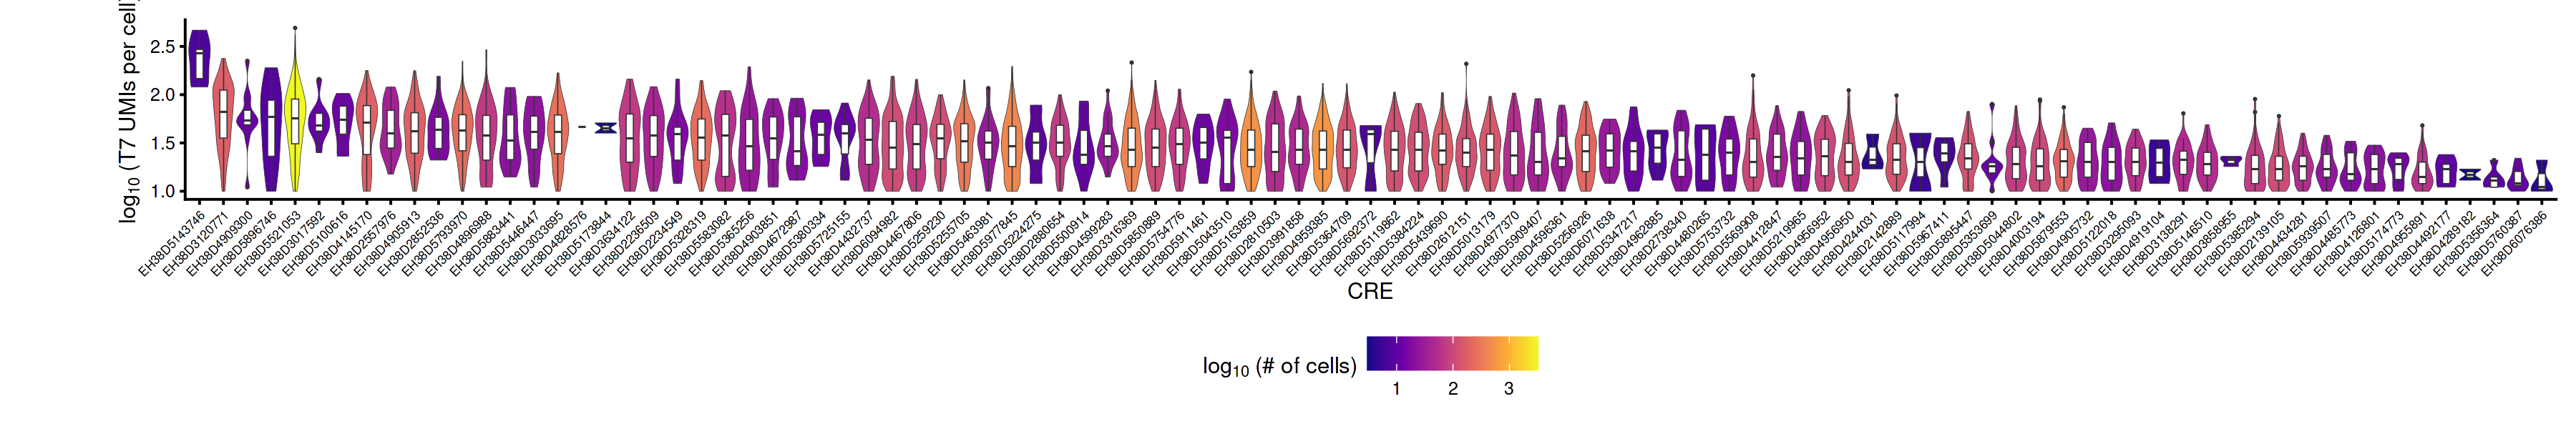

In [13]:
t7$n.cells <- n_cells$n.cells[match(t7$CRE,n_cells$CRE)]

a <- ggplot(t7, aes(x = reorder(CRE, -umis, FUN = mean), 
               y = log10(umis),
               fill = log10(n.cells))) +

  geom_violin(scale="width", linewidth = .1)+
  geom_boxplot(width=.3,fill="white", linewidth = .2,outlier.size=.1) +
  scale_fill_viridis_c(option = "plasma") +
  theme_classic() +
  theme(plot.margin = margin(t = 10, r = 10, b = 10, l = 60),
    axis.text.x = element_text(size= 6, angle = 45, hjust = 1),legend.position="bottom"
  ) +
  labs(fill = bquote(log[10]~"(# of cells)"), x = "CRE", y = bquote(log[10]~"(T7 UMIs per cell)")) 

options(repr.plot.width = 18, repr.plot.height = 3, repr.plot.res = 200)
a

Fold change in mean T7 UMIs (EH38D3120771 / EH38D5879553): 3.413503 


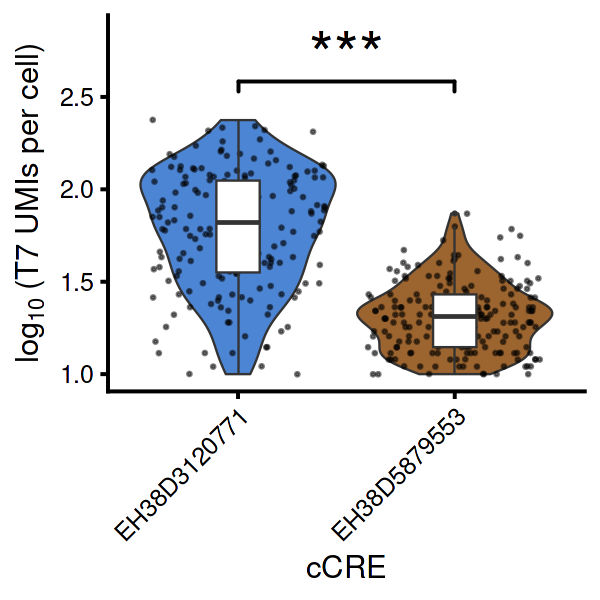

In [14]:
c_ <- c(
  "#62c251", "#aa4ac1", "#a8b635", "#5b66e1", "#d7a336", "#417eed",
  "#d97f2e", "#9b67e1", "#47963c", "#cf43a8", "#54c79a", "#e44586",
  "#317341", "#d980dd", "#5f7b2b", "#5553b7", "#8db870", "#a9519c",
  "#409775", "#d34250", "#42c0c7", "#ce4c2b", "#4d85d5", "#beaa62",
  "#8d82dd", "#79702a", "#7a559d", "#9c642e", "#56a7d9", "#e58e6e",
  "#4769a2", "#ab544f", "#a19ee0", "#b2386a", "#cc8ec7", "#994f72",
  "#e4819f"
)

y_max <- log10(max(t7[t7$CRE %in% c("EH38D3120771","EH38D5879553"),]$umis))
set.seed(200)

b <- ggplot(t7[t7$CRE %in% c("EH38D3120771","EH38D5879553"),] , aes(x = reorder(CRE, -umis, FUN = mean), 
               y = log10(umis),
               fill = CRE)) +

  geom_violin(scale="width",linewidth=.3)+
  geom_jitter(size=.2,alpha=.5) +
  geom_boxplot(width=.2,fill="white",linewidth=.3,outlier.size=.1) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    #text = element_text(size = 24),
      legend.position="none"
  ) +
  labs(fill = "# of cells", x = "cCRE", y = bquote(log[10]~"(T7 UMIs per cell)")) + 
  scale_fill_manual(values=sample(c_,2)) +
  geom_signif(
    comparisons = list(c("EH38D3120771", "EH38D5879553")),
    test = "wilcox.test",
    map_signif_level = TRUE,
    textsize = 8,
    y_position = 1.05*y_max
  ) +
expand_limits(y = 1.2*y_max)

options(repr.plot.width = 3, repr.plot.height = 3, repr.plot.res = 200)
b

mean_vals <- with(t7[t7$CRE %in% c("EH38D3120771","EH38D5879553"),],
                  tapply(umis, CRE, mean))
fc <- mean_vals["EH38D3120771"] / mean_vals["EH38D5879553"]
cat("Fold change in mean T7 UMIs (EH38D3120771 / EH38D5879553):", fc, "\n")


In [15]:
GetGC <- function(bsgenome, gr){
  seqs <- BSgenome::getSeq(bsgenome, gr)
  return(as.numeric(Biostrings::letterFrequency(x = seqs, letters = "GC", as.prob = TRUE)))
}

norm_mat <- GetAssayData(obj, assay = "RNA", layer = "data")

t7_exp <- as.data.frame(matrix(ncol=0,nrow=0))
for (CRE in n_cells[n_cells$n.cells >= 20,]$CRE) {
    try({
    CRE_gene <- unique(obj@meta.data[obj@meta.data$CRE_id == CRE,]$CRE_gene)
        
        
        
    CRE_range <- unique(obj@meta.data[obj@meta.data$CRE_id == CRE,]$CRE)
    CRE_range <- Signac::StringToGRanges(CRE_range, sep = c("-","-"))
    start(CRE_range) <- end(CRE_range) 
    end(CRE_range) <- start(CRE_range) + 200
    #CRE_range <- GenomicRanges::shift(CRE_range, -2000)    

    GC <- as.numeric(GetGC(bsgenome = BSgenome.Hsapiens.UCSC.hg38, gr = CRE_range))

    exp.df <- as.data.frame(norm_mat[CRE_gene,])
    colnames(exp.df) <- "exp"
    
    avg_exp <- mean(exp.df$exp)
    
    avg_t7 <- mean(t7[t7$CRE == CRE,]$umis)
        
        
    t7_exp <- rbind(t7_exp,c(CRE,
                             avg_exp,
                             avg_t7,
                             unique(obj@meta.data[obj@meta.data$CRE_id == CRE,]$CRE),
                             GC))

    })
}

colnames(t7_exp) <- c("CRE","gene_exp","t7_umis","range","GC")

Error in h(simpleError(msg, call)) : 
  error in evaluating the argument 'x' in selecting a method for function 'as.data.frame': subscript out of bounds
Error in h(simpleError(msg, call)) : 
  error in evaluating the argument 'x' in selecting a method for function 'as.data.frame': subscript out of bounds
Error in h(simpleError(msg, call)) : 
  error in evaluating the argument 'x' in selecting a method for function 'as.data.frame': subscript out of bounds
Error in h(simpleError(msg, call)) : 
  error in evaluating the argument 'x' in selecting a method for function 'as.data.frame': subscript out of bounds
Error in h(simpleError(msg, call)) : 
  error in evaluating the argument 'x' in selecting a method for function 'as.data.frame': subscript out of bounds
Error in h(simpleError(msg, call)) : 
  error in evaluating the argument 'x' in selecting a method for function 'as.data.frame': subscript out of bounds
Error in h(simpleError(msg, call)) : 
  error in evaluating the argument 'x' in se

Warning message in cor.test.default(log10(t7_exp$t7_umis), t7_exp$GC, method = "spearman"):
“Cannot compute exact p-value with ties”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <81>”


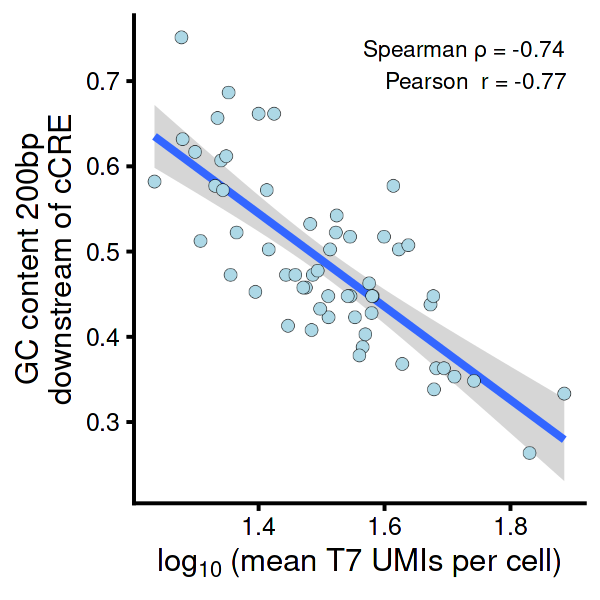

In [16]:
t7_exp$gene_exp <- as.numeric(t7_exp$gene_exp)
t7_exp$t7_umis <- as.numeric(t7_exp$t7_umis)
t7_exp$GC <- as.numeric(t7_exp$GC)


cor_spear <- cor.test(log10(t7_exp$t7_umis), t7_exp$GC, method = "spearman")
cor_pear  <- cor.test(log10(t7_exp$t7_umis), t7_exp$GC, method = "pearson")


c <- ggplot(t7_exp, aes(x = log10(t7_umis), y = GC)) +
  geom_smooth(method='lm', formula= y~x)+
  geom_point_rast(size=2,shape=21,fill="lightblue", stroke = .1) +
  annotate(
    "text",
    x = Inf, y = Inf,
    hjust = 1.1, vjust = 1.5,
    label = paste0(
      "Spearman ρ = ", round(cor_spear$estimate, 2),
      #"\np-value = ", signif(cor_spear$p.value, 2),
      "\nPearson  r = ", round(cor_pear$estimate, 2)
      #"\np-value = ", signif(cor_pear$p.value, 2)
    ),
    size = 8/.pt
  ) +
  theme_classic() +
  theme(
      legend.position="none"
  ) +
  labs(x = expression(log[10]~"(mean T7 UMIs per cell)"), y = "GC content 200bp\ndownstream of cCRE")

options(repr.plot.width = 3, repr.plot.height = 3, repr.plot.res = 200)
c

Warning message in cor.test.default(log10(t7_exp$t7_umis), log10(t7_exp$n.cells), :
“Cannot compute exact p-value with ties”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = 0.22' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = 0.22' in 'mbcsToSbcs': dot substituted for <81>”


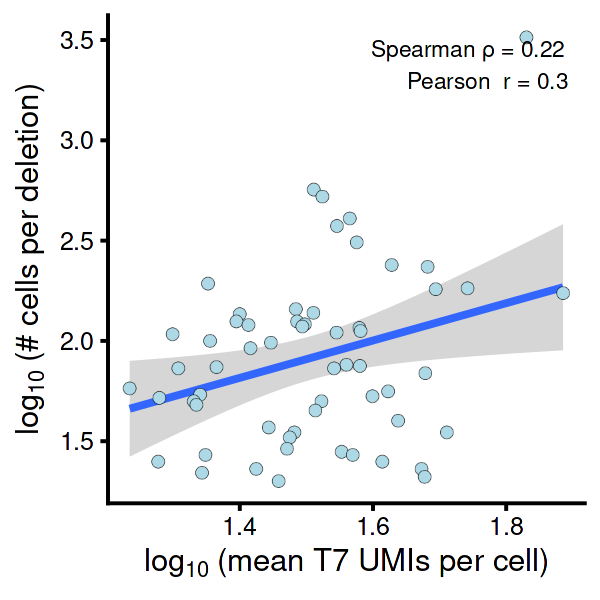

In [17]:
t7_exp$n.cells <- n_cells$n.cells[match(t7_exp$CRE,n_cells$CRE)]
t7_exp$gene_exp <- as.numeric(t7_exp$gene_exp)
t7_exp$t7_umis <- as.numeric(t7_exp$t7_umis)
t7_exp$GC <- as.numeric(t7_exp$GC)


cor_spear <- cor.test(log10(t7_exp$t7_umis), log10(t7_exp$n.cells), method = "spearman")
cor_pear  <- cor.test(log10(t7_exp$t7_umis), log10(t7_exp$n.cells), method = "pearson")


d <- ggplot(t7_exp, aes(x = log10(t7_umis), y = log10(n.cells))) +
  geom_smooth(method='lm', formula= y~x)+

  geom_point_rast(size=2,shape=21,fill="lightblue", stroke = .1) +
  annotate(
    "text",
    x = Inf, y = Inf,
    hjust = 1.1, vjust = 1.5,
    label = paste0(
      "Spearman ρ = ", round(cor_spear$estimate, 2),
      #"\np-value = ", signif(cor_spear$p.value, 2),
      "\nPearson  r = ", round(cor_pear$estimate, 2)
      #"\np-value = ", signif(cor_pear$p.value, 2)
    ),
    size = 8/.pt
  ) +
  theme_classic() +

  theme(
    #text = element_text(size = 24),
      legend.position="none"
  ) +
  labs(x = expression(log[10]~"(mean T7 UMIs per cell)"), y = expression(log[10]~"(# cells per deletion)"))

options(repr.plot.width = 3, repr.plot.height = 3, repr.plot.res = 200)
d

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <81>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = 0.22' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = 0.22' in 'mbcsToSbcs': dot substituted for <81>”


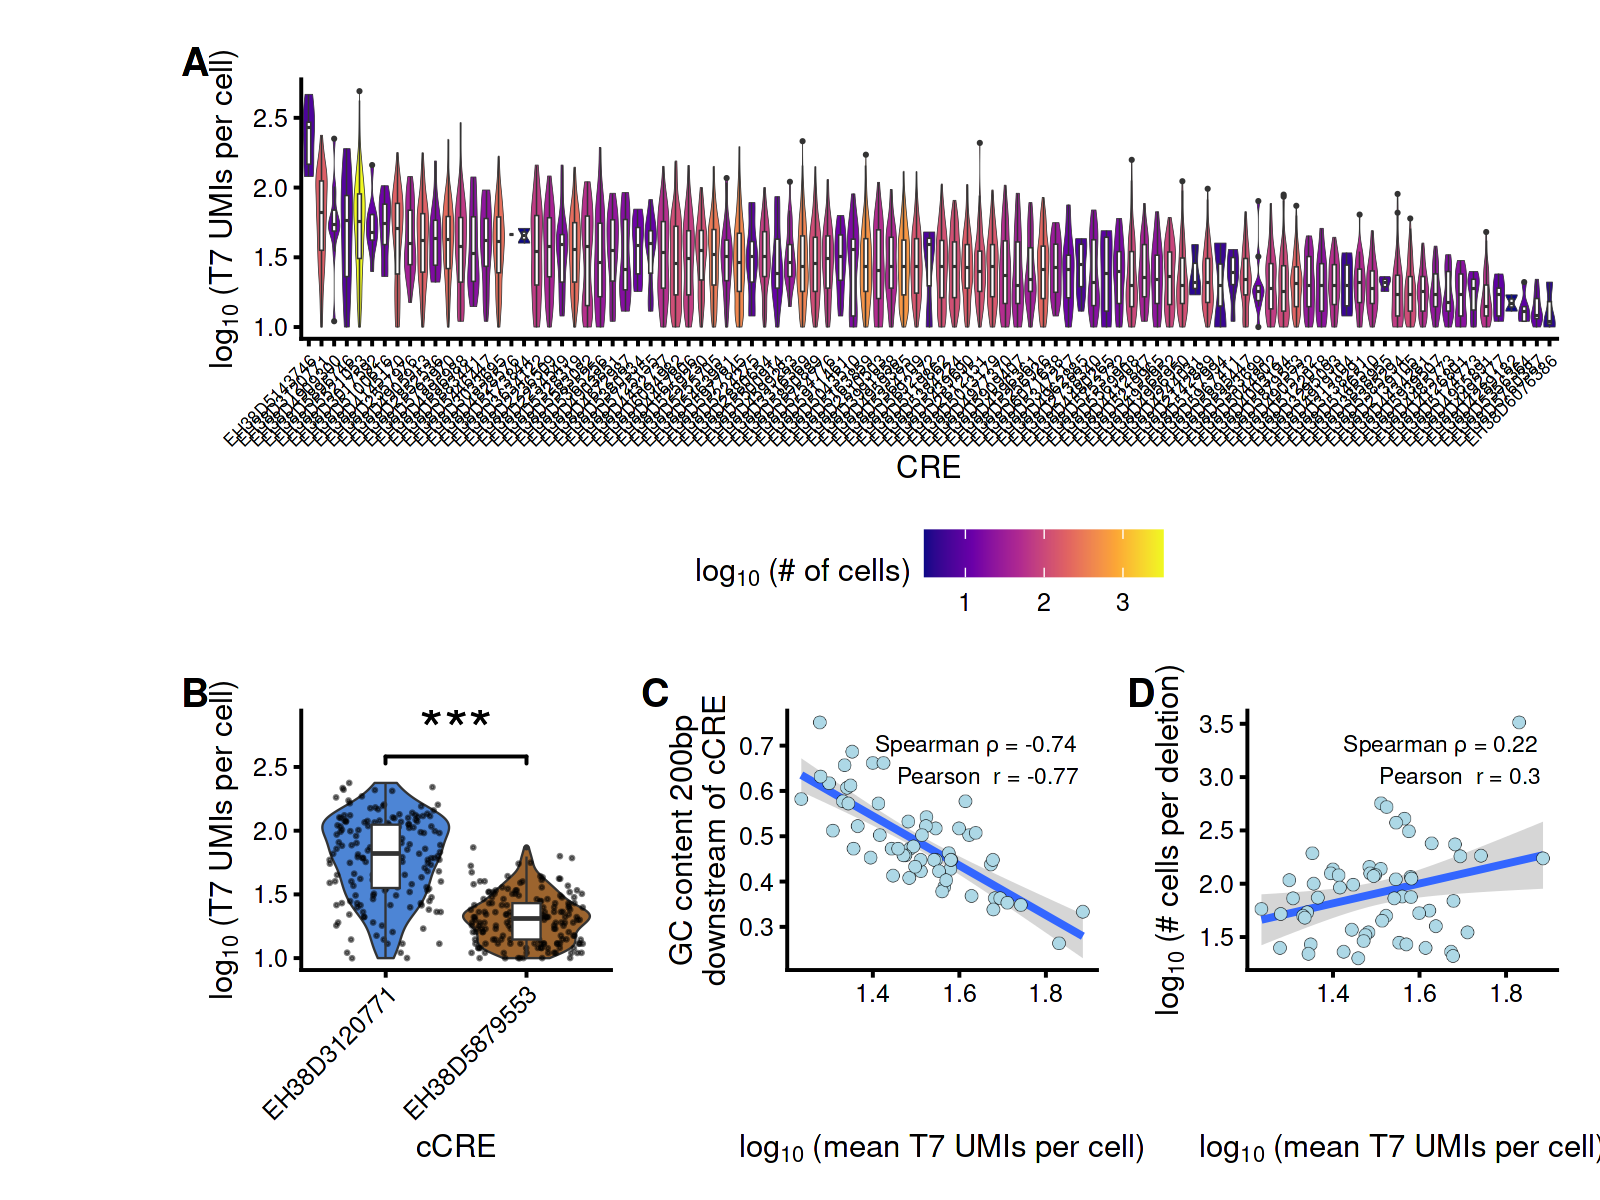

In [18]:
library(patchwork)

layout <- "
AAA
BCD
"


options(repr.plot.width = 8, repr.plot.height = 6, repr.plot.res = 200)
fig <- (a + b + c + d) +
  plot_layout(design = layout) +
  plot_annotation(tag_levels = "A") &
  theme(
    plot.tag = element_text(
      face = "bold",
      size = 14
    )
  )
fig

In [19]:
ggsave('../figures/SuppFig12.pdf', 
       plot = fig, 
       width = 235, 
       height = 175, 
       useDingbats = F, 
       units = 'mm', 
       device = 'pdf')

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <81>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <cf>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = -0.74' in 'mbcsToSbcs': dot substituted for <81>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Spearman ρ = 0.22' in 'mbcsToSbcs': dot substitu

## Figure 4
### UMAP of cells 

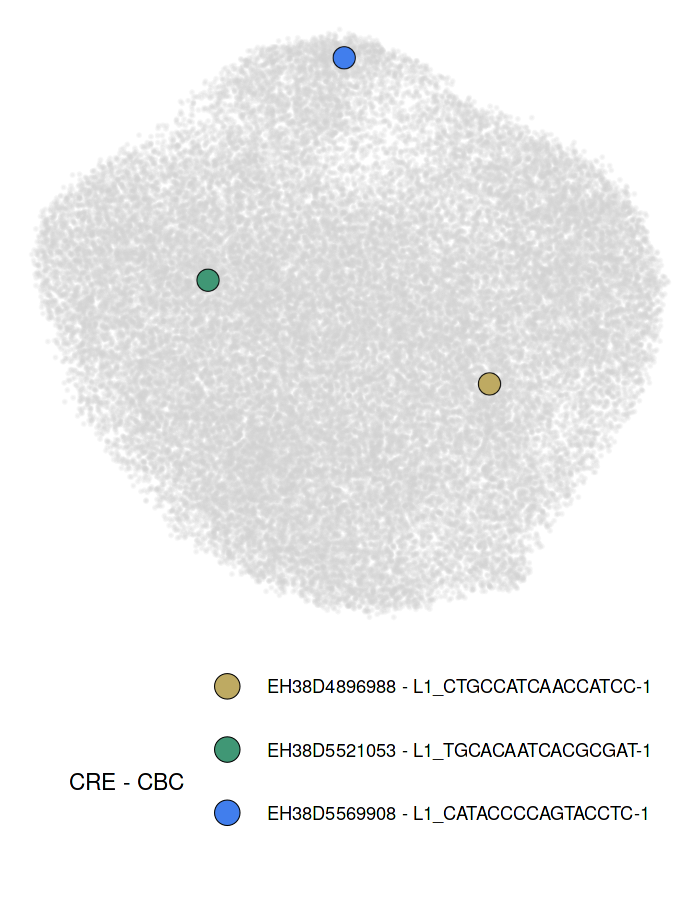

In [6]:
cells <- c("TGCACAATCACGCGAT-1","CATACCCCAGTACCTC-1","CTGCCATCAACCATCC-1")
cells <- paste0("L1_",cells)

cells_df <- obj@meta.data[cells,c("CRE_id","CRE","cbc")]


c_ <- c('#beaa62','#409775','#417eed')

UMAP.df <- as.data.frame(obj[["umap"]]@cell.embeddings)
colnames(UMAP.df) <- c("UMAP1", "UMAP2")
UMAP.df$CBC <- row.names(UMAP.df)

UMAP.df$CRE <- cells_df$CRE_id[match(rownames(UMAP.df),rownames(cells_df))]

UMAP.df$CRE <- paste0(UMAP.df$CRE, " - ", rownames(UMAP.df))

options(repr.plot.width = 3.5, repr.plot.height = 4.5, repr.plot.res = 200)
q <- ggplot() +
 geom_point_rast(data = UMAP.df[grepl("NA",UMAP.df$CRE) == TRUE,], aes(x=UMAP1,y=UMAP2),
            color="lightgrey",size=.1,alpha=.2) +
 geom_point_rast(data = UMAP.df[grepl("NA",UMAP.df$CRE) == FALSE,], aes(x=UMAP1,y=UMAP2,fill=CRE),
            color="black",shape=21,size=3.5,stroke=.2) +
 theme_void() +
 theme(text=element_text(size = 8),
      plot.title = element_text(hjust = 0.5),
      legend.position = "bottom") + 
 scale_fill_manual(values=c_) + 
 guides(fill = guide_legend(nrow = 4, override.aes = list(size = 4))) +
 labs(fill="CRE - CBC")
 #labs(color = x_label)
 q

### Differential expression testing of genes within 1Mb of targeted cCREs
Performing DE testing for target CREs with ≥100 cells and only looking at genes that are within 1Mb of the targeted CRE. 

First, just getting the locations of TSS's:

In [5]:
# Build transcript-level TSS once (from your same GENCODE GTF)
make_transcript_tss <- function(gtf) {
  tx <- gtf[gtf$type == "transcript"]
  biotype_col <- if ("gene_type" %in% names(mcols(tx))) "gene_type" else "gene_biotype"
  tx <- tx[mcols(tx)[[biotype_col]] == "protein_coding"]
  tx <- keepStandardChromosomes(tx, pruning.mode = "coarse")
  seqlevelsStyle(tx) <- "UCSC"
  tss_tx <- promoters(tx, upstream = 1, downstream = 1)
  # unpack tags into a simple character vector when present
  if ("tag" %in% names(mcols(tss_tx))) {
    tss_tx$tag_str <- vapply(mcols(tss_tx)$tag, function(x) paste0(x, collapse=","), "")
  } else {
    tss_tx$tag_str <- ""
  }
  tss_tx
}

# Helper: pick one transcript TSS for a gene (MANE > APPRIS principal > closest-to-CRE)
select_one_tss <- function(tss_tx_gene, CRE_mid) {
  if (length(tss_tx_gene) == 0) return(NULL)
  # 1) MANE Select
  mane_idx <- grepl("MANE_Select", tss_tx_gene$tag_str, fixed = TRUE)
  if (any(mane_idx)) return(tss_tx_gene[which(mane_idx)[1]])
  # 2) APPRIS principal
  appr_idx <- grepl("appris_principal", tss_tx_gene$tag_str, fixed = TRUE)
  if (any(appr_idx)) return(tss_tx_gene[which(appr_idx)[1]])
  # 3) Closest transcript TSS to the CRE midpoint
  d <- abs(start(tss_tx_gene) - start(CRE_mid)[1])
  return(tss_tx_gene[which.min(d)])
}


# FINAL: signed distance (transcript-aware)
get_signed_distance_tx <- function(gene, CRE_range, tss_tx) {
    
  CRE_gr  <- Signac::StringToGRanges(CRE_range, sep = c("-", "-"))
  CRE_mid <- resize(CRE_gr, width = 1, fix = "center")

  # transcripts for this gene (GENCODE uses 'gene_name')
  gene_hits <- which(mcols(tss_tx)$gene_name == gene)
  tss_tx_gene <- tss_tx[gene_hits]

  # same chromosome only
  tss_tx_gene <- tss_tx_gene[as.character(seqnames(tss_tx_gene)) == as.character(seqnames(CRE_mid))[1]]
  if (length(tss_tx_gene) == 0) return(NA_integer_)

  tss_one <- select_one_tss(tss_tx_gene, CRE_mid)
  if (is.null(tss_one)) return(NA_integer_)

  as.integer(start(tss_one) - start(CRE_mid)[1])
}
                             
get_nearby_genes <- function(CRE,tss_gr) {
    CRE_range <- unique(obj@meta.data[obj@meta.data$CRE_id == CRE,]$CRE)
    CRE_range <- Signac::StringToGRanges(CRE_range, sep = c("-","-"))

    ### A) Distance-based (robust near chrom ends)
    hits <- distanceToNearest(tss_gr, CRE_range, ignore.strand = TRUE)
    near_idx <- queryHits(hits)[mcols(hits)$distance <= 1e6]   # 1,000,000 bp
    tss_near <- tss_gr[near_idx]

    ### B) Window-based (±1 Mb around the CRE)
    win <- resize(CRE_range, width = width(CRE_range) + 2e6, fix = "center")
    # If your seqinfo has seqlengths, you can also do: win <- trim(win)
    tss_near_win <- subsetByOverlaps(tss_gr, win, ignore.strand = TRUE)

    genes <- unique(as.data.frame(tss_near_win)$gene_name)
    genes <- genes[genes %in% rownames(obj)]

    genes 
    }
                             
gtf_file <- "../19K-intronic_K562-3N-3d-T7/gencode.v44.basic.annotation.gtf"
gtf <- import(gtf_file) 
                             
tss_tx_gr <- make_transcript_tss(gtf)

Performing the differential expression testing:

In [6]:
DefaultAssay(obj) <- "RNA"
CRE_de <- as.data.frame(matrix(ncol=0,nrow=0))

for (CRE in n_cells[n_cells$n.cells >= 100,]$CRE) {
    try({
    message(CRE)



    genes <- get_nearby_genes(CRE,tss_tx_gr)

    CRE_cells <- rownames(obj@meta.data[grepl(CRE,obj@meta.data$CRE_id) == TRUE,])

    # Get the total number of cells with a deletion for 
    # this CRE
    total.cells <- length(CRE_cells)

    # Get all cells assigned a deletion
    all_cells <- rownames(obj@meta.data[obj@meta.data$CRE_id != "",])
    all_cells <- all_cells[!(all_cells %in% CRE_cells)]

    # Get the gene that the deletion overlaps
    CRE_gene <- unique(obj@meta.data[obj@meta.data$CRE_id == CRE,]$CRE_gene)

    obj@meta.data$group <- ifelse(rownames(obj@meta.data) %in% CRE_cells, "deletion",
                           ifelse(obj@meta.data$CRE_id == "", "no deletion",""))
    Idents(obj) <- obj@meta.data$group

    de_ <- FindMarkers(obj,
                      ident.1 = "deletion",
                      ident.2 = "no deletion",
                      features = genes,
                      min.pct  = 0, 
                      logfc.threshold = 0, 
                      min.diff.pct    = -Inf)
    de_$CRE <- CRE
    de_$gene <- rownames(de_)
    rownames(de_) <- paste0(CRE,":",de_$gene)
    de_$CRE_gene <- CRE_gene
        
    de_$total_cells <- total.cells
        
    CRE_range <- unique(obj@meta.data[obj@meta.data$CRE_id == CRE,]$CRE)
    de_$distance <- vapply(de_$gene,
                           get_signed_distance_tx,
                           CRE_range = CRE_range,
                           tss_tx    = tss_tx_gr,
                           FUN.VALUE = integer(1))

    CRE_de <- rbind(CRE_de,de_)
    })
    }

EH38D5521053

EH38D4959385

EH38D5163859

EH38D5977845

EH38D3316369

EH38D5255705

EH38D3033695

EH38D5328319

EH38D5793970

EH38D5256926

EH38D5879553

EH38D4145170

EH38D4905913

EH38D3120771

EH38D5439690

EH38D5013179

EH38D5364709

EH38D2142889

EH38D5895447

EH38D2612151

EH38D5119862

EH38D4956950

EH38D5384224

EH38D5259230

EH38D6094982

EH38D5850889

EH38D2139105

EH38D4003194



In [7]:
plot_df <- CRE_de
plot_df <- plot_df[(plot_df$pct.1 >= .05 | plot_df$pct.2 >= .05),]


plot_df$type <- ifelse(
    plot_df$avg_log2FC <= log2(.85) &
    (plot_df$pct.1 >= .05 | plot_df$pct.2 >= .05) &
    plot_df$p_val < .05,
    "nominal p < 0.05 & ≥15% decrease",
    "other genes"
)

plot_df$type <- factor(
    plot_df$type,
    levels = c("nominal p < 0.05 & ≥15% decrease", "other genes")
)

plot_df$direction <- ifelse(plot_df$type == "nominal p < 0.05 & ≥15% decrease" & plot_df$avg_log2FC < 0,"down","up")

options(repr.plot.width = 6, repr.plot.height = 2.5, repr.plot.res = 200)
a <- ggplot(plot_df[rev(order(plot_df$type)),],
       aes(x=distance,y=(2^avg_log2FC - 1) * 100,
           fill=type,
           shape=direction)) + 
       geom_hline(yintercept=0,linetype="dashed") +
       geom_point_rast(size=2,alpha=.7,color="black",stroke=.2) + 
       scale_fill_manual(values=c("salmon","lightgrey")) +
       theme_classic() +
       scale_shape_manual(values = c("down" = 23, "up" = 21)) + 
       theme(text = element_text(size = 8),
              axis.line  = element_line(color = "black"),
              axis.text  = element_text(size = 8),
              axis.title = element_text(size = 8),
              plot.title = element_text(size = 8),
              legend.position="bottom")  + 
      labs(fill="") + 
      xlab("gene TSS distance from cCRE midpoint") + 
      ylab("% change in expression")+ 
      scale_y_continuous(breaks = seq(-50, 125, by = 25)) +
      guides(fill  = guide_legend(override.aes = list(shape = 21, color = "black", size = 3), nrow = 2),
             shape = "none") + guides(
  fill = guide_legend(
    override.aes = list(
      shape = c(23, 21),  # diamond, circle
      color = "black",
      size = 3
    ),
    nrow = 2
  ),
  shape = "none"
)

In [8]:
emp_fdr <- readRDS("../top-100_10X-capture/empirical_fdr_results.wilcox.rds")
emp_fdr$eg_pair <- paste0(emp_fdr$CRE,"_",emp_fdr$gene)

emp_fdr_plot <- function(eg,
                         df = emp_fdr,
                         p_cut = 0.05,
                         direction = c("auto","down","up"),
                         n_null_label = 1000) {

  direction <- match.arg(direction)

  d <- df[df$eg_pair == eg, ]
  if (nrow(d) == 0) stop("No rows found for eg_pair = ", eg)

  # pull gene/CRE for labels
  gene <- unique(d$gene)[1]
  cre  <- unique(d$CRE)[1]

  # identify the true deletion row
  true_row <- d[d$type == "true deletion", ]
  if (nrow(true_row) != 1) stop("Expected exactly 1 'true deletion' row for ", eg)

  true_p  <- true_row$p_val[1]
  true_fc <- true_row$avg_log2FC[1]

  # choose direction
  if (direction == "auto") {
    dir_use <- ifelse(true_fc < 0, "down", "up")
  } else {
    dir_use <- direction
  }

  # directional null/background set
  if (dir_use == "down") {
    null_bg <- d[d$type != "true deletion" & d$avg_log2FC < 0, ]
    # as-or-more-extreme (more negative FC AND p as small or smaller)
    null_as_extreme <- nrow(null_bg[null_bg$p_val <= true_p &
                                    null_bg$avg_log2FC <= true_fc, ])
    # highlighted quadrant = upper-left
    rect_xmin <- -Inf; rect_xmax <- 0
  } else { # up
    null_bg <- d[d$type != "true deletion" & d$avg_log2FC > 0, ]
    null_as_extreme <- nrow(null_bg[null_bg$p_val <= true_p &
                                    null_bg$avg_log2FC >= true_fc, ])
    # highlighted quadrant = upper-right
    rect_xmin <- 0; rect_xmax <- Inf
  }

  total_null <- nrow(null_bg)
  emp_fdr_val <- (null_as_extreme + 1) / (total_null + 1)

  # symmetric x-limits
  xlim_val <- max(abs(d$avg_log2FC), na.rm = TRUE)

  # label text
  fdr_lab <- sprintf("directional FDR (%s) = %.3f", dir_use, emp_fdr_val)
  nnull_lab <- sprintf("(n directional null tests = %s)", total_null)
  d <- d[order(d$type == "true deletion"), ]  
  d$type <- factor(d$type, levels = c("sim deletion", "true deletion"))
  ggplot(d, aes(x = avg_log2FC, y = -log10(p_val), fill = type)) +

    # highlight the relevant quadrant above p_cut
    annotate("rect",
             xmin = rect_xmin, xmax = rect_xmax,
             ymin = -log10(p_cut), ymax = Inf,
             fill = "salmon", alpha = 0.1) +

    geom_hline(yintercept = -log10(p_cut), linetype = "dashed") +
    geom_vline(xintercept = 0,             linetype = "dashed") +

    geom_point_rast(size = 2, color = "black", shape = 21,stroke=.2) +

    theme_classic() +
    theme(
          axis.line  = element_line(color = "black"),
#           axis.text  = element_text(size = 8),
#           axis.title = element_text(size = 8),
          plot.title = element_text(size = 9),
          legend.position = "bottom") +

    xlab(bquote(log[2]*"FC(GEx)")) +
    ylab(bquote("-"~log[10]~"(p-value)")) +

    xlim(-xlim_val, xlim_val) +

    scale_fill_manual(values = c("true deletion" = "red",
                                 "sim deletion"  = "lightgrey")) +

    labs(fill = "permutation status",
         title = paste0(cre, " : ", gene)) +

    guides(fill = guide_legend(override.aes = list(size = 3), nrow = 2)) +
    labs(subtitle = sprintf("directional FDR (%s) = %.3f\n(n directional null tests = %s)",
                          dir_use, emp_fdr_val, total_null)) +
     theme(plot.subtitle = element_text(hjust = 0,size=9))
#     annotate("text",
#              x = rect_xmin, y = Inf,
#              label = fdr_lab,
#              hjust = -0.05, vjust = 3, size = 4) +
#     annotate("text",
#              x = rect_xmin, y = Inf,
#              label = nnull_lab,
#              hjust = -0.05, vjust = 5, size = 4)
}

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'nominal p < 0.05 & ≥15% decrease' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'nominal p < 0.05 & ≥15% decrease' in 'mbcsToSbcs': dot substituted for <89>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'nominal p < 0.05 & ≥15% decrease' in 'mbcsToSbcs': dot substituted for <a5>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'nominal p < 0.05 & ≥15% decrease' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'nominal p < 0.05 & ≥15% decrease' in 'mbcsToSbcs': dot substituted for <89>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“co

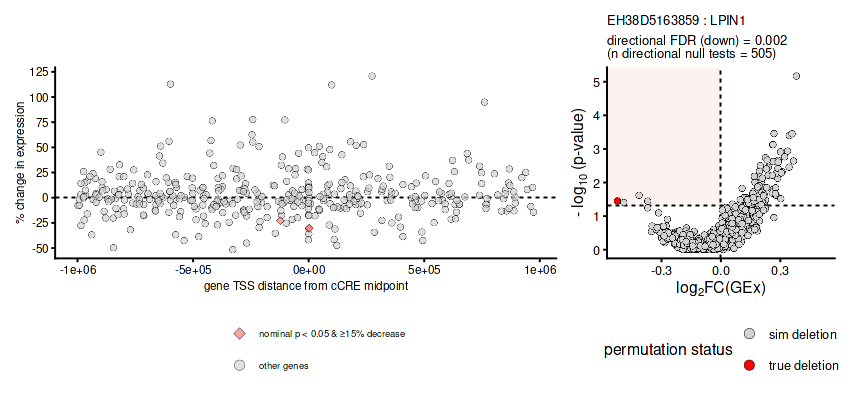

In [9]:
b <- emp_fdr_plot("EH38D5163859_LPIN1")

layout <- "
AB
"


fig <- a + b +
  plot_layout(
    design = layout,
    widths = c(2.75, 1.25)
  )

options(repr.plot.width = 8.5, repr.plot.height = 4, repr.plot.res = 100)
fig

### Supplementary Figure 14
First the FDR from running the analysis using permuted deletion identities (vs WT cells) for the testing:

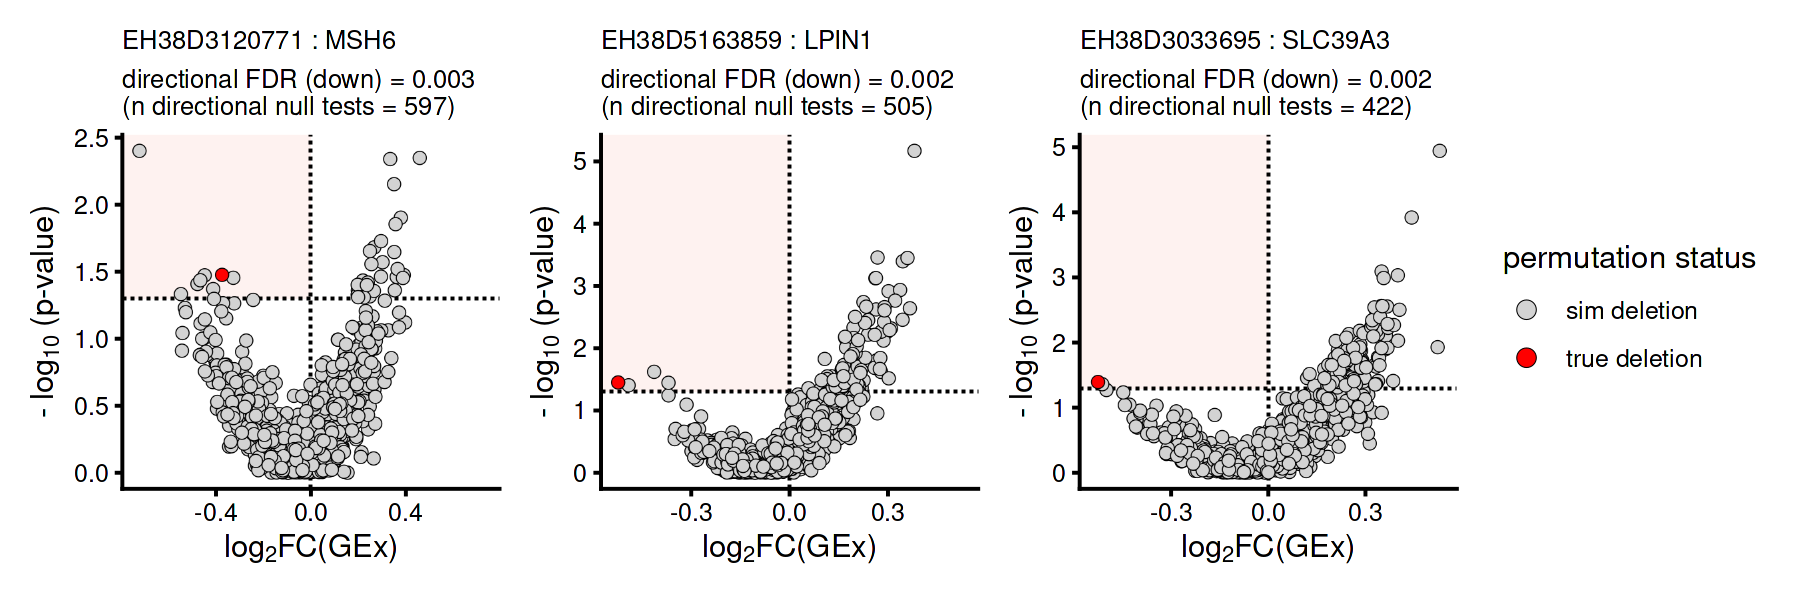

In [10]:
# First dataset determines the order
emp_fdr <- readRDS("../top-100_10X-capture/empirical_fdr_results.wilcox.rds")
emp_fdr$eg_pair <- paste0(emp_fdr$CRE, "_", emp_fdr$gene)

egs <- with(
    subset(emp_fdr, type == "true deletion" & p_val < 0.05),
    unique(eg_pair[order(p_val)])
)

plots <- lapply(egs, emp_fdr_plot)

permute_fdr <- wrap_plots(
    plots,
    ncol = 3,
    guides = "collect"
) &
    theme(legend.position = "right")

options(repr.plot.width = 9, repr.plot.height = 3, repr.plot.res = 200)
permute_fdr

Also looking at the FDR when using WT cells vs all other cells for the testing:

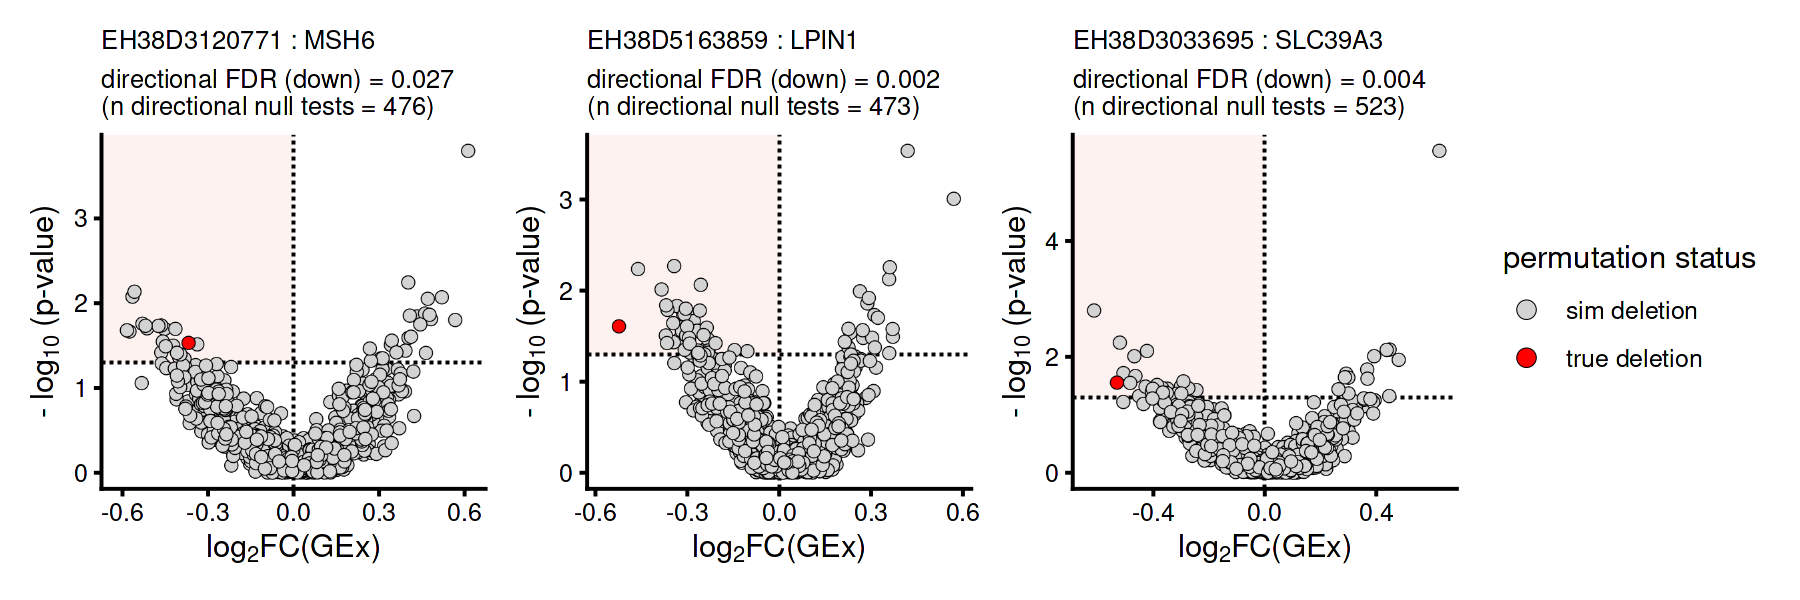

In [11]:
emp_fdr <- readRDS("../top-100_10X-capture/empirical_fdr_results.wilcox.WT-null.rds")
emp_fdr$eg_pair <- paste0(emp_fdr$CRE, "_", emp_fdr$gene)

plots <- lapply(egs, emp_fdr_plot)

wt_fdr <- wrap_plots(
    plots,
    ncol = 3,
    guides = "collect"
) &
    theme(legend.position = "right")

options(repr.plot.width = 9, repr.plot.height = 3, repr.plot.res = 200)
wt_fdr

In [12]:
sampling_out <- readRDS("../top-100_10X-capture/downsampled_de_results.rds")
unique(sampling_out$gene)

# fold-change per run
sampling_out$FC <- 2^(sampling_out$avg_log2FC)

# split by gene + n_sampled
sp <- split(sampling_out$FC, list(sampling_out$gene, sampling_out$n_sampled), drop = TRUE)

# build summary table
sum_list <- lapply(names(sp), function(nm) {
  x <- sp[[nm]]
  parts <- strsplit(nm, "\\.")[[1]]   # aggregate split names use "."
  data.frame(
    gene = parts[1],
    n_sampled = as.numeric(parts[2]),
    mean = mean(x, na.rm = TRUE),
    lo = unname(quantile(x, 0.025, na.rm = TRUE)),
    hi = unname(quantile(x, 0.975, na.rm = TRUE))
  )
})

sum_df <- do.call(rbind, sum_list)

options(repr.plot.width = 4, repr.plot.height = 2, repr.plot.res = 200)

a <- ggplot(sum_df, aes(x = n_sampled, y = mean, color = gene, fill = gene)) +
  geom_ribbon(aes(ymin = lo, ymax = hi), alpha = 0.2, color = NA) +
  geom_line(linewidth = 1) +
  geom_point(size = 1) +
  theme_classic() +
  labs(
    x = "Number of deletion cells sampled",
    y = "Fold-change",
    color = "Gene",
    fill  = "Gene"
  ) +
  scale_color_manual(values=c("#028be0","red","#e8b705")) + 
  scale_fill_manual(values=c("#028be0","red","#e8b705"))
library(ggplot2)

# transform p-values
sampling_out$neglog10_p <- -log10(sampling_out$p_val)

# summarize across the 100 samplings
sum_df <- aggregate(
  neglog10_p ~ gene + n_sampled,
  data = sampling_out,
  FUN = function(x) {
    c(mean = mean(x, na.rm = TRUE),
      lo   = unname(quantile(x, 0.025, na.rm = TRUE)),
      hi   = unname(quantile(x, 0.975, na.rm = TRUE)))
  }
)

# unpack the matrix column
sum_df$mean <- sum_df$neglog10_p[, "mean"]
sum_df$lo   <- sum_df$neglog10_p[, "lo"]
sum_df$hi   <- sum_df$neglog10_p[, "hi"]
sum_df$neglog10_p <- NULL


options(repr.plot.width = 4, repr.plot.height = 2, repr.plot.res = 200)

# plot
b <- ggplot(sum_df, aes(x = n_sampled, y = mean, color = gene, fill = gene)) +
  geom_ribbon(aes(ymin = lo, ymax = hi), alpha = 0.2, color = NA) +
  geom_line(linewidth = 1) +
  geom_point(size = 1) +
  geom_hline(yintercept = -log10(0.05), linetype = "dotted") +
  theme_classic() +
  labs(
    x = "Number of deletion cells sampled",
    y = bquote("-"~log[10]~"(p-value)"),
    color = "Gene",
    fill  = "Gene"
  )+
  scale_color_manual(values=c("#028be0","red","#e8b705")) + 
  scale_fill_manual(values=c("#028be0","red","#e8b705"))

[1] "LPIN1"   "SLC39A3" "MSH6"

In [13]:
# Getting the top captured deletion barcodes for LPIN1 (EH38D5163859)
freq <- as.data.frame(table(obj@meta.data[grepl("EH38D5163859",obj@meta.data$CRE_id),]$location_barcode))
colnames(freq) <- c("barcode","n_cells")
freq <- freq[grepl("_",freq$barcode) == FALSE &
             freq$n_cells > 50,]

barcodes <- freq$barcode

de_out <- as.data.frame(matrix(ncol=0,nrow=0))
for (barcode in barcodes) {
    message(barcode)
    obj@meta.data$group <- ifelse(grepl(barcode,obj@meta.data$location_barcode) == TRUE, "deletion",
                           ifelse(obj@meta.data$location_barcode == "", "WT", "other"))
    Idents(obj) <- obj@meta.data$group
    

    de_ <- FindMarkers(obj,
                      ident.1 = "deletion",
                      ident.2 = "WT",
                      features = "LPIN1",
                      min.pct  = 0, 
                      logfc.threshold = 0, 
                      min.diff.pct    = -Inf)
    
    de_$location_barcode <- barcode
    de_$gene <- rownames(de_)
    rownames(de_) <- paste0(barcode,":",de_$gene)
    de_out <- rbind(de_out,de_)                              
}


pattern <- paste(barcodes, collapse = "|")

obj@meta.data$group <- ifelse(
    grepl(pattern, obj@meta.data$location_barcode),
    "deletion",
    ifelse(obj@meta.data$location_barcode == "", "WT", "other")
)

Idents(obj) <- obj@meta.data$group


de_ <- FindMarkers(obj,
                  ident.1 = "deletion",
                  ident.2 = "WT",
                  features = "LPIN1",
                  min.pct  = 0, 
                  logfc.threshold = 0, 
                  min.diff.pct    = -Inf)

de_$location_barcode <- "all three"
de_$gene <- rownames(de_)
rownames(de_) <- paste0("all three",":",de_$gene)
de_out <- rbind(de_out,de_)    

chr2-11744387-AAGGTGA

chr2-11744387-GGCTTCT

chr2-11744387-TGCGCCT



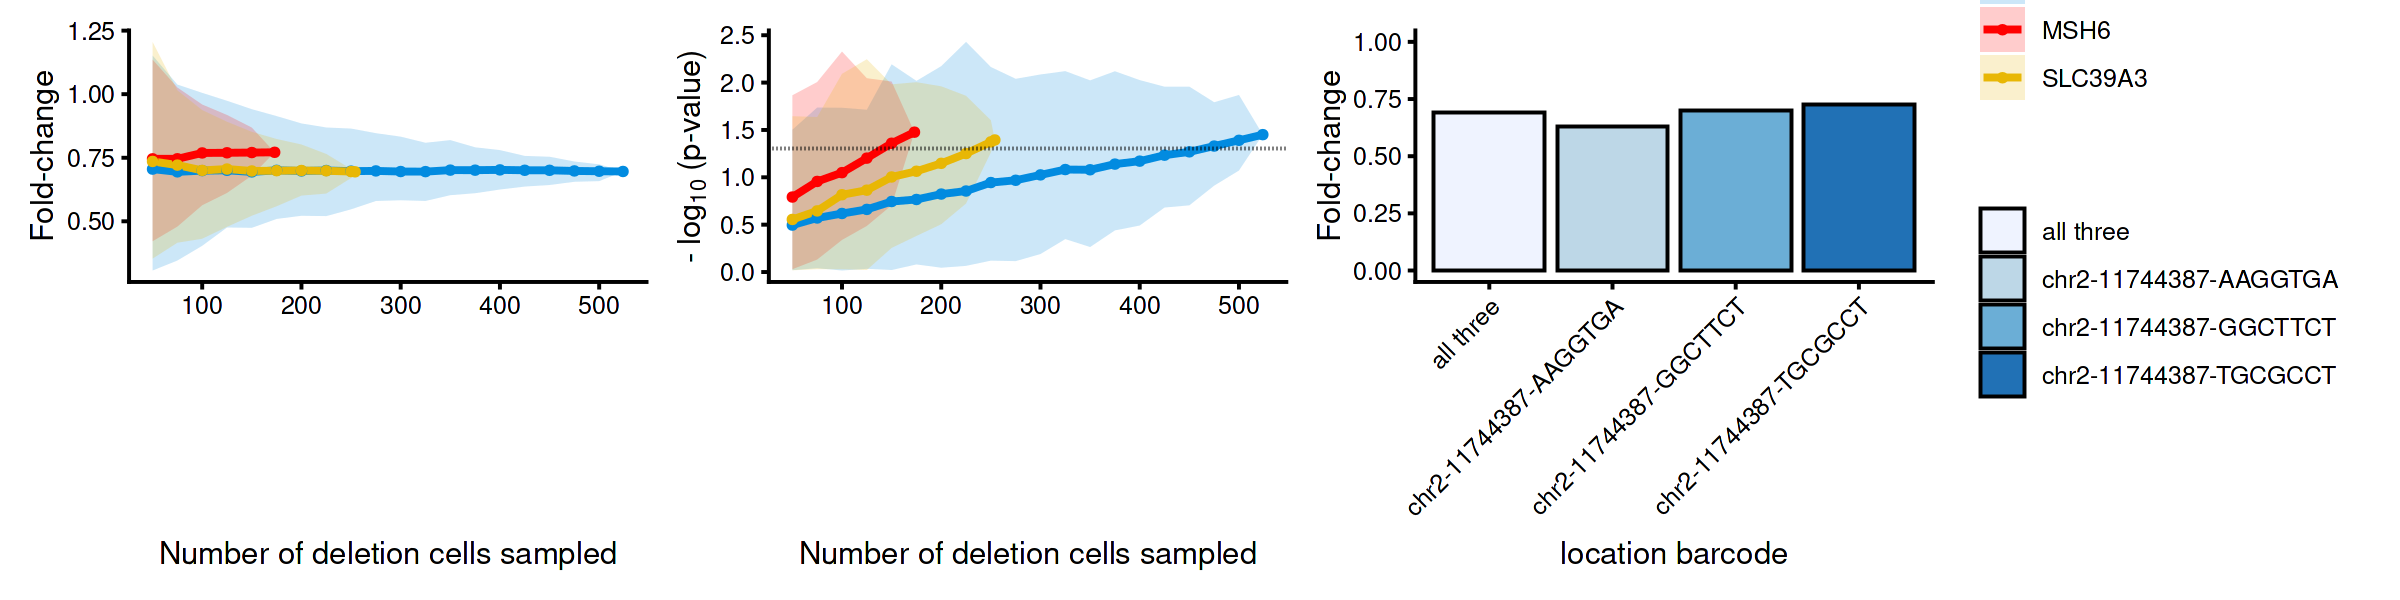

In [14]:
lpin1_barcodes <- ggplot(de_out, aes(x = location_barcode,
                               y = 2^avg_log2FC,
                               fill = location_barcode)) +
                geom_col(color="black") +
                scale_fill_brewer(palette = "Blues") +
                theme_classic() +
                theme(
                    legend.position="none",
                    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1)
                ) + ylim(0,1) + ylab("Fold-change") + xlab("location barcode") + labs(fill="")

downsample_fig <- (a + b + lpin1_barcodes) +
  plot_layout(
    design = "
ABC
",
    guides = "collect"
  ) &
  theme(legend.position = "right")

options(repr.plot.width = 12, repr.plot.height = 3, repr.plot.res = 200)
downsample_fig


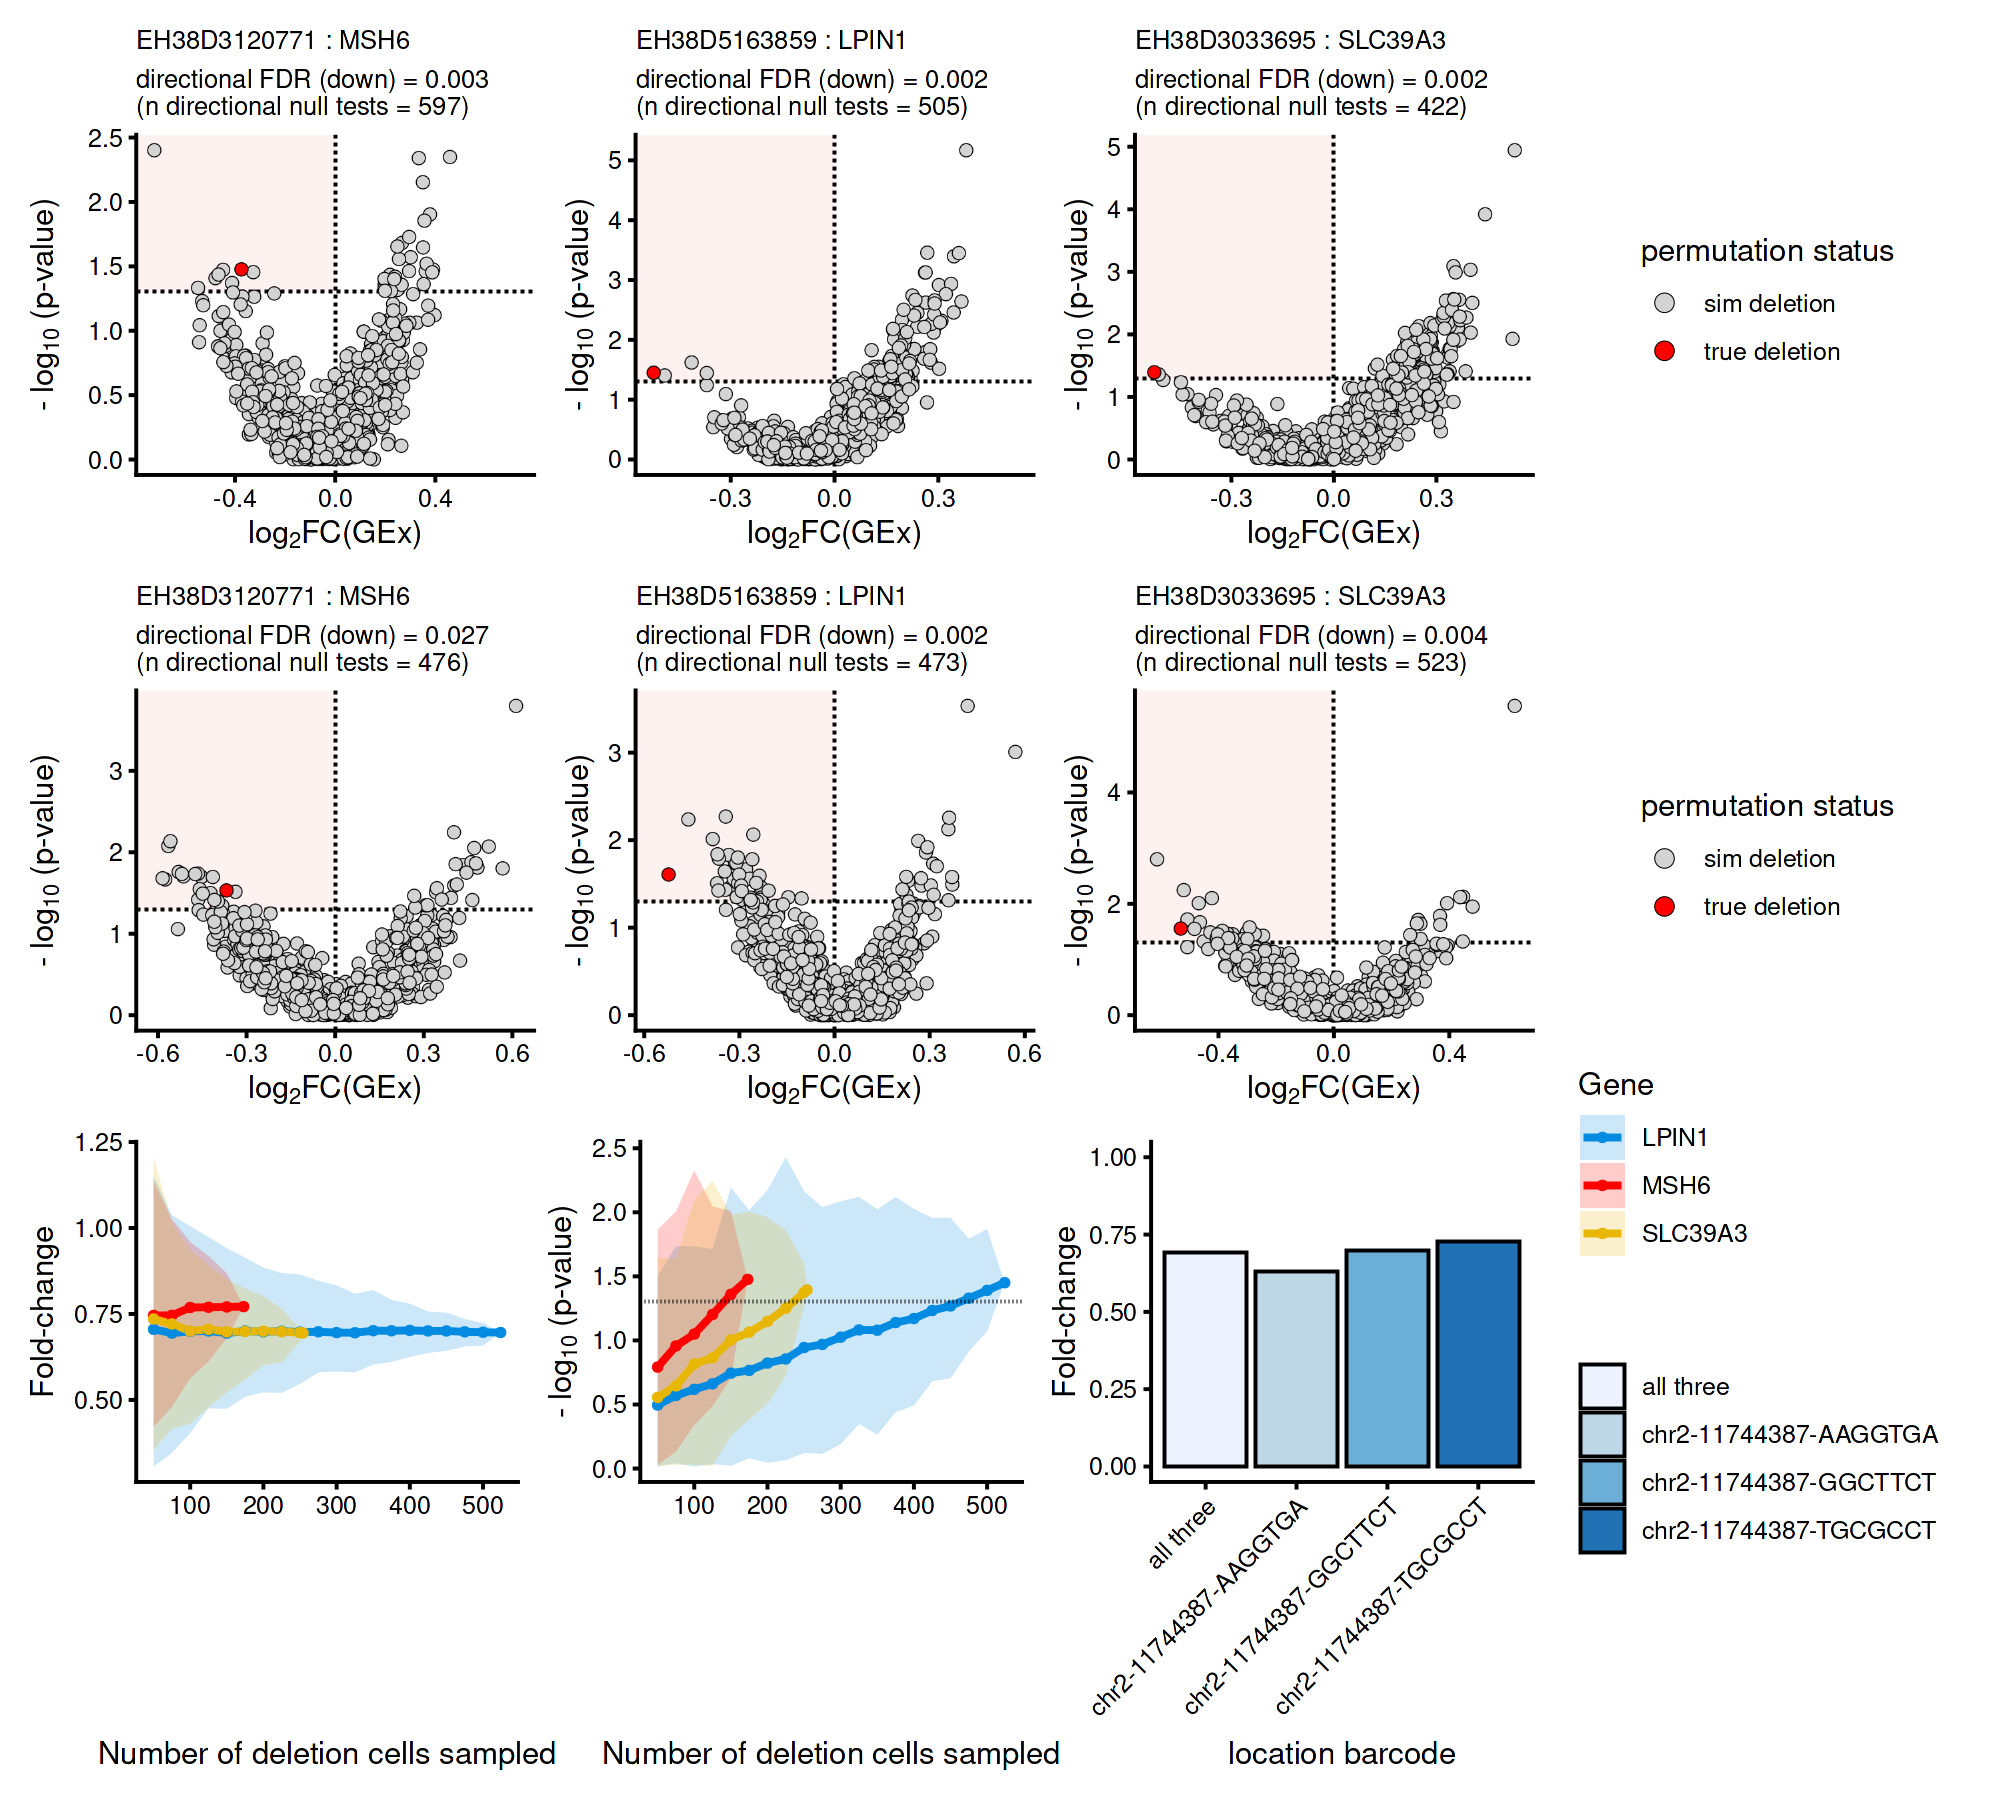

In [15]:
fig <- permute_fdr / wt_fdr / downsample_fig 
options(repr.plot.width = 10, repr.plot.height = 9, repr.plot.res = 200)
fig

In [16]:
ggsave('../figures/SuppFig14.pdf', plot = fig, width = 210, height = 190, useDingbats = F, units = 'mm', device = 'pdf')

In [17]:
emp_fdr <- readRDS("../top-100_10X-capture/empirical_fdr_results.wilcox.rds")

for (gene in unique(emp_fdr[emp_fdr$p_val < .05 & emp_fdr$type != "sim deletion",]$gene)) {
    
    # subsetting FDR results to gene in question
    sub <- emp_fdr[emp_fdr$gene == gene,]
    
    # further subsetting to simulated deletions (null distribution)
    sub_null <- sub[sub$type == "sim deletion",]
    
    # also subsetting to the true deletion
    sub_true <- sub[sub$type != "sim deletion",]
    
    # getting the true deletions FC and p-value
    true_FC <- sub_true$avg_log2FC
    true_P <- sub_true$p_val
    
    # getting total number of null tests
    n_null <- nrow(sub_null)
    
    # getting the total number of null tests with downregulation 
    # (whether significant or not)
    n_null_down <- nrow(sub_null[sub_null$avg_log2FC < 0,])
    
    # getting number of null tests with a significant p-value 
    # (both upregulation and downregulation)
    n_null_sig <- nrow(sub_null[sub_null$p_val < .05,])
    
    # getting the number of null tests with a signficant p-value and down regulation
    n_null_sig_down <- nrow(sub_null[sub_null$p_val < .05 & sub_null$avg_log2FC < 0,])
    
    # getting the number of null tests with a p-value and effect size
    # both as large as true deletion
    n_null_match <- nrow(sub_null[sub_null$p_val <= true_P & sub_null$avg_log2FC <= true_FC,])

    # getting the number of null tests with a signficant p-value (<.05) and effect size
    # as large
    n_null_match_effect <- nrow(sub_null[sub_null$p_val <= .05 & sub_null$avg_log2FC <= true_FC,])
    
    pct <- function(x, denom) {sprintf("%.2f%%", 100 * x / denom)}

    cat("\n")
    cat("Gene:", gene, "\n")
    cat("CRE:", paste(unique(sub_true$CRE), collapse = ", "), "\n")
    cat("True deletion:\n")
    cat("  avg_log2FC:", sprintf("%.3f", true_FC), "\n")
    cat("  p_val:", signif(true_P, 3), "\n")
    cat("\n")

    cat("Null distribution summary:\n")
    cat("  Total null tests:", n_null, "\n")
    cat("  Null tests with negative FC:",
        n_null_down, paste0("(", pct(n_null_down, n_null), ")"), "\n")
    cat("  Null tests with p_val < 0.05:",
        n_null_sig, paste0("(", pct(n_null_sig, n_null), ")"), "\n")
    cat("  Null tests with p_val < 0.05 and negative FC:",
        n_null_sig_down, paste0("(", pct(n_null_sig_down, n_null), ")"), "\n")
    cat("  Null tests with p_val <= true p_val and avg_log2FC <= true avg_log2FC:",
        n_null_match, paste0("(", pct(n_null_match, n_null), ")"), "\n")
    cat("  Null tests with p_val < 0.05 and avg_log2FC <= true avg_log2FC:",
        n_null_match_effect, paste0("(", pct(n_null_match_effect, n_null), ")"), "\n")
    cat("\n")
    
    }


Gene: LPIN1 
CRE: EH38D5163859 
True deletion:
  avg_log2FC: -0.523 
  p_val: 0.0354 

Null distribution summary:
  Total null tests: 1000 
  Null tests with negative FC: 505 (50.50%) 
  Null tests with p_val < 0.05: 106 (10.60%) 
  Null tests with p_val < 0.05 and negative FC: 3 (0.30%) 
  Null tests with p_val <= true p_val and avg_log2FC <= true avg_log2FC: 0 (0.00%) 
  Null tests with p_val < 0.05 and avg_log2FC <= true avg_log2FC: 0 (0.00%) 


Gene: SLC39A3 
CRE: EH38D3033695 
True deletion:
  avg_log2FC: -0.526 
  p_val: 0.0403 

Null distribution summary:
  Total null tests: 1000 
  Null tests with negative FC: 422 (42.20%) 
  Null tests with p_val < 0.05: 118 (11.80%) 
  Null tests with p_val < 0.05 and negative FC: 1 (0.10%) 
  Null tests with p_val <= true p_val and avg_log2FC <= true avg_log2FC: 0 (0.00%) 
  Null tests with p_val < 0.05 and avg_log2FC <= true avg_log2FC: 0 (0.00%) 


Gene: MSH6 
CRE: EH38D3120771 
True deletion:
  avg_log2FC: -0.374 
  p_val: 0.0334 

Null 

In [20]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] cowplot_1.2.0                     ggrastr_1.0.2                    
 [3] patchwork_1.3.2                   BSgenome.Hsapiens.UCSC.hg38_1.4.5
 